# Political trust in Germany: East vs West (raw data)

Follow-up to `political_trust_de_fr.ipynb`, narrowed to Germany and split into the former
East and West. **Raw data only — no model.** The question is simply whether an East/West
divide in institutional trust is visible in the ESS data, and whether it has moved over
2002–2023.

Same two dimensions as before, following Valgarðsson et al. (2025):
**representative** institutions (`trstprl` parliament, `trstplt` politicians, `trstprt`
parties) and **implementing** institutions (`trstlgl` legal system, `trstplc` police).

## Do we have the required data? Yes

Two complementary region columns cover every German respondent with no gaps:

| rounds | column | coding |
| --- | --- | --- |
| 1–4 (2002–2008) | `regionde` | numeric 1–16, labelled in the codebook |
| 5–11 (2010–2023) | `region` | NUTS-1 codes `DE1`–`DEG` |

Both resolve to the 16 Bundesländer, which map cleanly onto East/West — with one genuine
ambiguity (Berlin) handled explicitly below.

## Two caveats that shape everything here

1. **Berlin cannot be split.** Neither column separates former East from former West Berlin.
   Berlin is therefore kept as its own third category and excluded from the East/West
   comparison, rather than being silently assigned to one side. (ESS does publish an
   `intewde` East/West interview flag in some rounds, which would resolve this — it is not
   in this data subset.)
2. **The East oversample was discontinued.** East respondents are ~32% of the German sample
   in rounds 1–8 but only ~14% from round 9 on. Since East trust is persistently lower, this
   composition shift *by itself* pushes unweighted national averages upward. Quantified below.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "../literature/ESS_Dataset/Datafile-subset.csv"

REP_ITEMS = ["trstprl", "trstplt", "trstprt"]  # representative institutions
IMP_ITEMS = ["trstlgl", "trstplc"]  # implementing institutions
TRUST_ITEMS = REP_ITEMS + IMP_ITEMS

REGION_COLORS = {"West": "#1f77b4", "East": "#d62728", "Berlin": "#7f7f7f"}

# Documented ESS fieldwork start years; the file itself carries no survey year
# (`proddate` is the publication date). Round 10 was COVID-delayed into 2021-22.
ROUND_YEARS = {
    1: 2002, 2: 2004, 3: 2006, 4: 2008, 5: 2010, 6: 2012,
    7: 2014, 8: 2016, 9: 2018, 10: 2020, 11: 2023,
}

df = pd.read_csv(DATA_PATH, low_memory=False)
de = df[df["cntry"] == "DE"].copy()
de["essround"] = de["essround"].astype(int)
de["year"] = de["essround"].map(ROUND_YEARS)

# 77 = refusal, 88 = don't know, 99 = no answer, blank = not asked -> NaN
for col in TRUST_ITEMS:
    de[col] = pd.to_numeric(de[col], errors="coerce")
    de.loc[de[col].isin([77, 88, 99]), col] = np.nan

print(f"German respondents: {len(de):,}")
de[["essround", "year", "region", "regionde"] + TRUST_ITEMS].head()

German respondents: 36,845


,essround,year,region,regionde,trstprl,trstplt,trstprt,trstlgl,trstplc
0,1,2002,NaN,1.0,0.0,0.0,NaN,6.0,9.0
1,1,2002,NaN,1.0,7.0,4.0,NaN,7.0,10.0
2,1,2002,NaN,1.0,4.0,4.0,NaN,9.0,6.0
3,1,2002,NaN,1.0,6.0,2.0,NaN,8.0,8.0
4,1,2002,NaN,1.0,3.0,1.0,NaN,4.0,4.0


## Building the Bundesland variable

`regionde` numeric labels are taken from the dataset codebook (`Datafile-subset codebook.html`),
not guessed — the numbering is **not** alphabetical and not the NUTS order, so guessing it
would silently misclassify rounds 1–4.

In [2]:
# regionde: numeric codes, rounds 1-4 (verbatim from the codebook)
REGIONDE_LABELS = {
    1: "Schleswig-Holstein", 2: "Hamburg", 3: "Niedersachsen", 4: "Bremen",
    5: "Nordrhein-Westfalen", 6: "Hessen", 7: "Rheinland-Pfalz",
    8: "Baden-Wuerttemberg", 9: "Bayern", 10: "Saarland", 11: "Berlin",
    12: "Brandenburg", 13: "Mecklenburg-Vorpommern", 14: "Sachsen",
    15: "Sachsen-Anhalt", 16: "Thueringen",
}

# region: NUTS-1 codes, rounds 5-11
NUTS1_LABELS = {
    "DE1": "Baden-Wuerttemberg", "DE2": "Bayern", "DE3": "Berlin", "DE4": "Brandenburg",
    "DE5": "Bremen", "DE6": "Hamburg", "DE7": "Hessen",
    "DE8": "Mecklenburg-Vorpommern", "DE9": "Niedersachsen",
    "DEA": "Nordrhein-Westfalen", "DEB": "Rheinland-Pfalz", "DEC": "Saarland",
    "DED": "Sachsen", "DEE": "Sachsen-Anhalt", "DEF": "Schleswig-Holstein",
    "DEG": "Thueringen",
}

# Five new Laender. Berlin is deliberately NOT in here -- see the intro.
EAST_LAENDER = {"Brandenburg", "Mecklenburg-Vorpommern", "Sachsen",
                "Sachsen-Anhalt", "Thueringen"}

de["land"] = de["region"].map(NUTS1_LABELS).fillna(de["regionde"].map(REGIONDE_LABELS))
de["ew"] = np.where(
    de["land"].isin(EAST_LAENDER), "East",
    np.where(de["land"] == "Berlin", "Berlin", "West"),
)

print(f"rows with no Bundesland assigned: {de['land'].isna().sum()}")
print("\nwhich column supplied the region, by round:")
src = pd.DataFrame({
    "n": de.groupby("essround").size(),
    "from region (NUTS-1)": de.groupby("essround")["region"].apply(lambda s: s.notna().sum()),
    "from regionde (numeric)": de.groupby("essround")["regionde"].apply(lambda s: s.notna().sum()),
})
print(src.to_string())

rows with no Bundesland assigned: 0

which column supplied the region, by round:
             n  from region (NUTS-1)  from regionde (numeric)
essround                                                     
1         2919                     0                     2919
2         2870                     0                     2870
3         2916                     0                     2916
4         2751                     0                     2751
5         3031                  3031                        0
6         2958                  2958                        0
7         3045                  3045                        0
8         2852                  2852                        0
9         2358                  2358                        0
10        8725                  8725                        0
11        2420                  2420                        0


## Sample composition — and why it matters for national trends

The East share of the German sample halves between round 8 and round 9. That is a design
change (the East oversample ending), not a population change: East Germany is roughly 17–20%
of the German adult population throughout.

respondents per region per round:
ew    West  East  Berlin
year                    
2002  1763   972     184
2004  1783   925     162
2006  1823   906     187
2008  1726   860     165
2010  1943   984     104
2012  1916   923     119
2014  1993   892     160
2016  1863   864     125
2018  1881   386      91
2020  7077  1263     385
2023  1991   347      82

share of the German sample (%):
ew    West  East  Berlin
year                    
2002  60.4  33.3     6.3
2004  62.1  32.2     5.6
2006  62.5  31.1     6.4
2008  62.7  31.3     6.0
2010  64.1  32.5     3.4
2012  64.8  31.2     4.0
2014  65.5  29.3     5.3
2016  65.3  30.3     4.4
2018  79.8  16.4     3.9
2020  81.1  14.5     4.4
2023  82.3  14.3     3.4


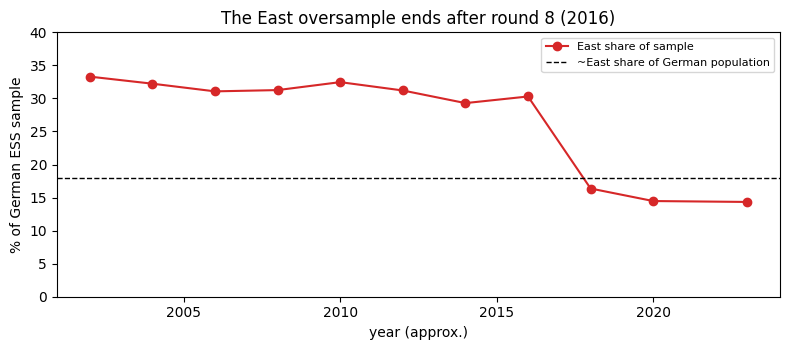

In [3]:
counts = pd.crosstab(de["year"], de["ew"])[["West", "East", "Berlin"]]
shares = (pd.crosstab(de["year"], de["ew"], normalize="index") * 100)[["West", "East", "Berlin"]]
print("respondents per region per round:")
print(counts.to_string())
print("\nshare of the German sample (%):")
print(shares.round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(shares.index, shares["East"], "-o", color=REGION_COLORS["East"], label="East share of sample")
ax.axhline(18, ls="--", c="k", lw=1, label="~East share of German population")
ax.set_ylabel("% of German ESS sample")
ax.set_xlabel("year (approx.)")
ax.set_title("The East oversample ends after round 8 (2016)")
ax.set_ylim(0, 40)
ax.legend(fontsize=8)
fig.tight_layout()

In [4]:
def weighted_mean_se(frame, col, wcol="pspwght"):
    """Weighted mean and naive standard error (assumes iid sampling within the group --
    no design-effect / clustering correction, so treat the bands as indicative)."""
    sub = frame[[col, wcol]].dropna()
    n = len(sub)
    if n == 0:
        return np.nan, np.nan, 0
    mean = np.average(sub[col], weights=sub[wcol])
    var = np.average((sub[col] - mean) ** 2, weights=sub[wcol])
    return mean, np.sqrt(var / n), n


# Dimension scores: a respondent's mean across the items they answered.
de["rep_score"] = de[REP_ITEMS].mean(axis=1)
de["imp_score"] = de[IMP_ITEMS].mean(axis=1)
DIMS = {"rep_score": "Representative", "imp_score": "Implementing"}


def by_region(col, regions=("West", "East")):
    """Weighted mean + SE of `col` per (region, year)."""
    rows = []
    for (reg, yr), g in de[de["ew"].isin(regions)].groupby(["ew", "year"]):
        m, se, n = weighted_mean_se(g, col)
        rows.append({"ew": reg, "year": yr, "mean": m, "se": se, "n": n})
    return pd.DataFrame(rows).sort_values(["ew", "year"])

### What the composition shift does to the national trend

This is a direct warning about the national model in `political_trust_de_fr.ipynb`, which was
fit **unweighted**. If the low-trust East is over-represented early and not late, the national
unweighted average drifts upward even when neither region moves.

In [5]:
rows = []
for yr, g in de.groupby("year"):
    sub = g.dropna(subset=["rep_score"])
    rows.append({
        "year": yr,
        "national (unweighted)": sub["rep_score"].mean(),
        "national (weighted)": np.average(sub["rep_score"], weights=sub["pspwght"]),
        "East": sub.loc[sub.ew == "East", "rep_score"].mean(),
        "West": sub.loc[sub.ew == "West", "rep_score"].mean(),
        "East share %": 100 * (sub.ew == "East").mean(),
    })
nat = pd.DataFrame(rows)
print("Representative trust, Germany (mean of 3 items, 0-10)")
print(nat.round(2).to_string(index=False))

chg = nat.iloc[-1] - nat.iloc[0]
print("\nchange 2002 -> 2023:")
for k in ["national (unweighted)", "national (weighted)", "East", "West"]:
    print(f"  {k:<24} {chg[k]:+.2f}")
print("\nThe unweighted national rise is much larger than either region's own rise --")
print("the signature of a composition shift rather than an attitude shift.")

Representative trust, Germany (mean of 3 items, 0-10)
 year  national (unweighted)  national (weighted)  East  West  East share %
 2002                   3.88                 3.94  3.47  4.11         33.20
 2004                   3.48                 3.53  3.27  3.62         32.35
 2006                   3.49                 3.58  3.06  3.74         31.26
 2008                   3.83                 3.88  3.51  3.97         31.34
 2010                   3.58                 3.65  3.14  3.80         32.64
 2012                   4.05                 4.07  3.65  4.22         31.27
 2014                   4.23                 4.28  3.74  4.46         29.39
 2016                   4.47                 4.48  4.01  4.67         30.27
 2018                   4.35                 4.26  3.76  4.45         16.32
 2020                   4.22                 4.09  3.71  4.30         14.34
 2023                   4.35                 4.09  3.59  4.47         14.33

change 2002 -> 2023:
  national (

## Raw trends by region

Survey-weighted means with ±1.96·SE bands. Berlin is excluded (it cannot be split); its series
is shown separately further down for completeness.

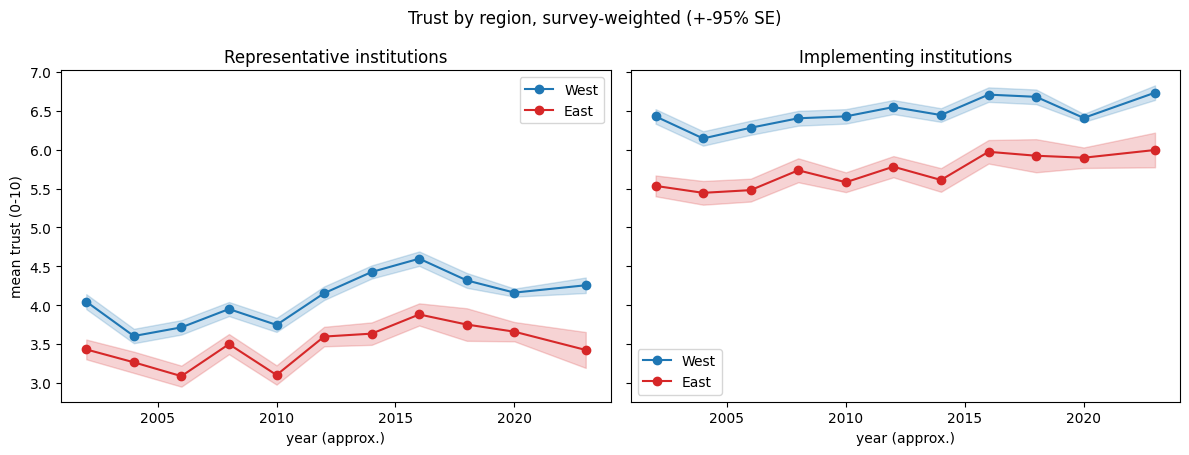

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, (col, title) in zip(axes, DIMS.items()):
    d = by_region(col)
    for reg in ["West", "East"]:
        s = d[d["ew"] == reg]
        ax.plot(s["year"], s["mean"], "-o", color=REGION_COLORS[reg], label=reg)
        ax.fill_between(s["year"], s["mean"] - 1.96 * s["se"], s["mean"] + 1.96 * s["se"],
                        color=REGION_COLORS[reg], alpha=0.2)
    ax.set_title(f"{title} institutions")
    ax.set_xlabel("year (approx.)")
    ax.legend()
axes[0].set_ylabel("mean trust (0-10)")
fig.suptitle("Trust by region, survey-weighted (+-95% SE)")
fig.tight_layout()

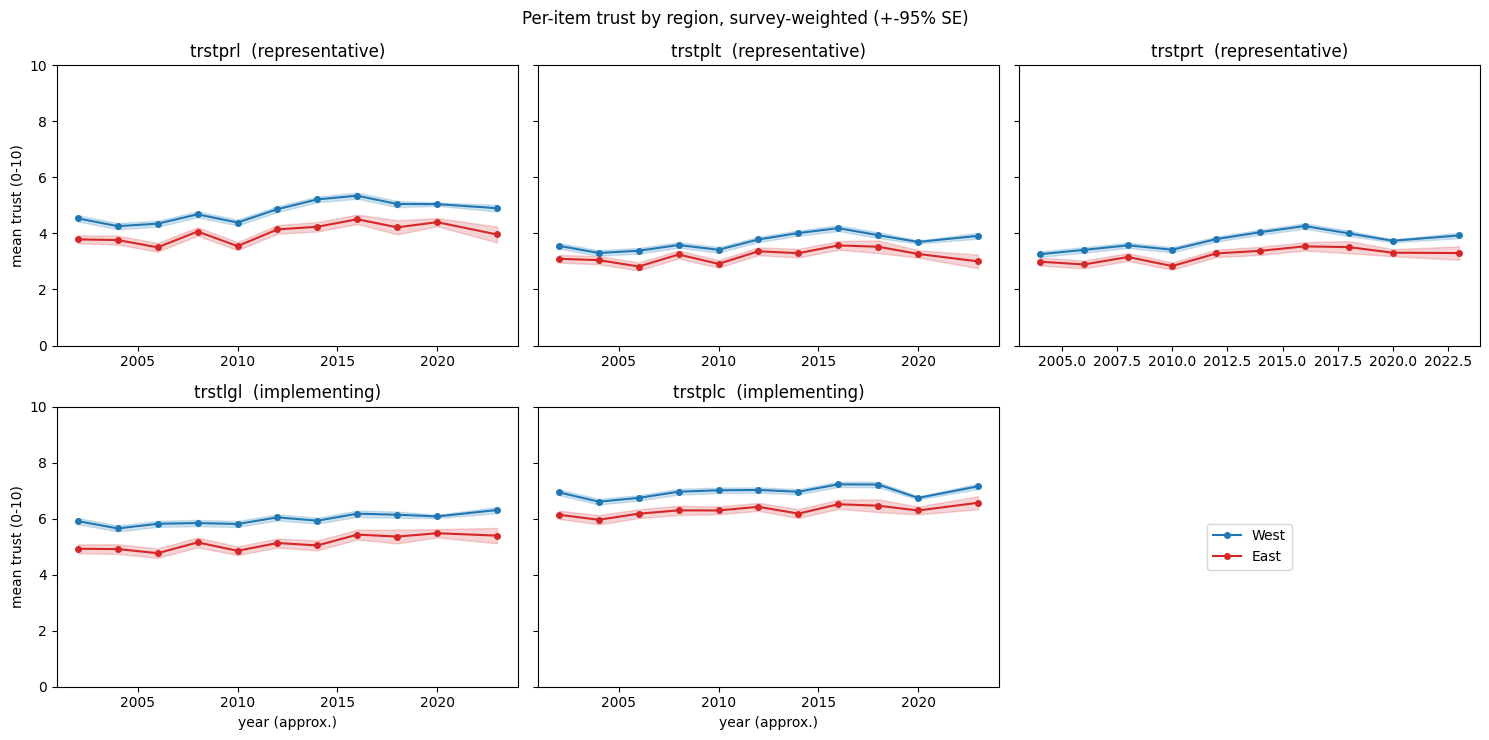

In [7]:
# Per-item detail: does the divide look the same for every institution?
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharey=True)
axes = axes.ravel()
for ax, item in zip(axes, TRUST_ITEMS):
    d = by_region(item)
    for reg in ["West", "East"]:
        s = d[d["ew"] == reg]
        ax.plot(s["year"], s["mean"], "-o", color=REGION_COLORS[reg], ms=4, label=reg)
        ax.fill_between(s["year"], s["mean"] - 1.96 * s["se"], s["mean"] + 1.96 * s["se"],
                        color=REGION_COLORS[reg], alpha=0.2)
    block = "representative" if item in REP_ITEMS else "implementing"
    ax.set_title(f"{item}  ({block})")
    ax.set_ylim(0, 10)
axes[5].axis("off")
axes[5].legend(*axes[0].get_legend_handles_labels(), loc="center")
axes[0].set_ylabel("mean trust (0-10)")
axes[3].set_ylabel("mean trust (0-10)")
for ax in axes[3:5]:
    ax.set_xlabel("year (approx.)")
fig.suptitle("Per-item trust by region, survey-weighted (+-95% SE)")
fig.tight_layout()

## The East–West gap over time

Unlike the cross-country comparison in the previous notebook, this one **is** legitimate:
East and West respondents answer the same questionnaire, in the same language, in the same
survey. There is no cross-national translation or response-scale problem to worry about.

`SE_gap = sqrt(SE_West² + SE_East²)`, treating the two subsamples as independent.

dimension  Implementing  Representative
year                                   
2002               0.89            0.61
2004               0.70            0.34
2006               0.80            0.63
2008               0.67            0.45
2010               0.85            0.64
2012               0.77            0.56
2014               0.83            0.79
2016               0.74            0.72
2018               0.76            0.57
2020               0.51            0.50
2023               0.74            0.83


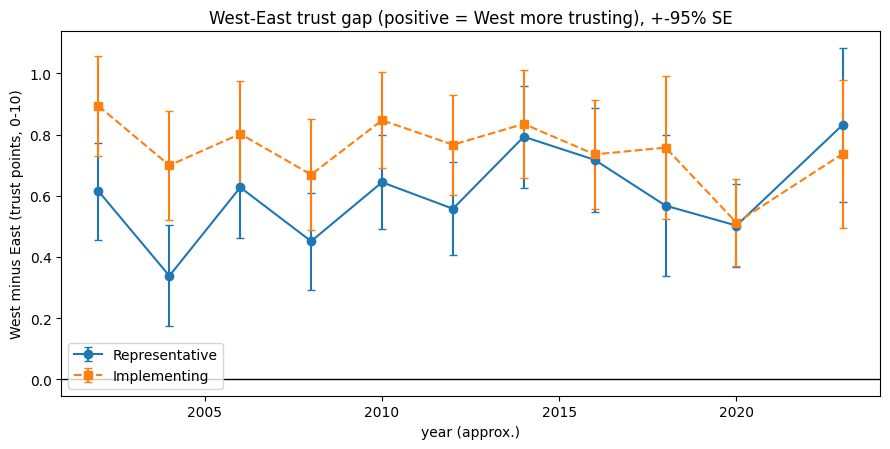

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.6))
gap_tbl = []
for (col, title), style in zip(DIMS.items(), ["-o", "--s"]):
    d = by_region(col)
    w = d[d.ew == "West"].set_index("year")
    e = d[d.ew == "East"].set_index("year")
    gap = w["mean"] - e["mean"]
    se = np.sqrt(w["se"] ** 2 + e["se"] ** 2)
    ax.errorbar(gap.index, gap, yerr=1.96 * se, fmt=style, capsize=3, label=title)
    gap_tbl.append(pd.DataFrame({"dimension": title, "year": gap.index,
                                 "gap": gap.values, "se": se.values}))
ax.axhline(0, c="k", lw=1)
ax.set_ylabel("West minus East (trust points, 0-10)")
ax.set_xlabel("year (approx.)")
ax.set_title("West-East trust gap (positive = West more trusting), +-95% SE")
ax.legend()
fig.tight_layout()

gap_tbl = pd.concat(gap_tbl, ignore_index=True)
print(gap_tbl.pivot(index="year", columns="dimension", values="gap").round(2).to_string())

## Is "East" homogeneous?

A single East/West dummy is only useful if the five new Länder actually behave alike. This
pools rounds 9–11 (the most recent, post-oversample period) and ranks all 16 Länder.

                  land  group  rep_trust   se    n
               Sachsen   East       3.50 0.08  685
            Thueringen   East       3.52 0.13  325
        Sachsen-Anhalt   East       3.55 0.11  333
Mecklenburg-Vorpommern   East       3.74 0.15  231
              Saarland   West       3.84 0.18  178
           Brandenburg   East       3.85 0.11  392
                Bayern   West       4.00 0.05 2222
                Hessen   West       4.17 0.07  950
         Niedersachsen   West       4.23 0.06 1359
       Rheinland-Pfalz   West       4.23 0.09  656
    Baden-Wuerttemberg   West       4.25 0.05 1803
   Nordrhein-Westfalen   West       4.25 0.04 2847
                Berlin Berlin       4.38 0.09  554
    Schleswig-Holstein   West       4.47 0.09  520
               Hamburg   West       4.74 0.14  275
                Bremen   West       4.78 0.26   55

Note the small n for several Laender -- these are sample splits of a survey
designed to be representative nationally, not per Land. 

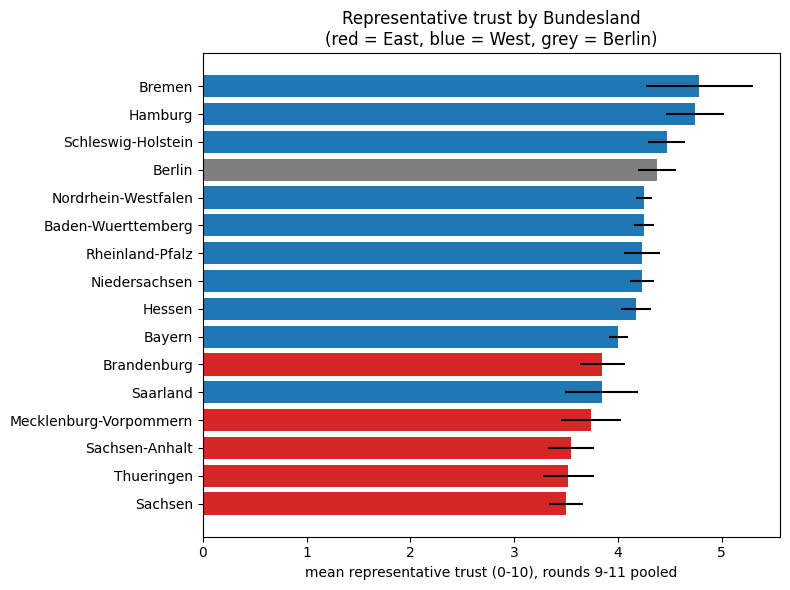

In [9]:
recent = de[de["essround"] >= 9]
rows = []
for land, g in recent.groupby("land"):
    m, se, n = weighted_mean_se(g, "rep_score")
    rows.append({"land": land, "group": g["ew"].iloc[0], "rep_trust": m, "se": se, "n": n})
land_tbl = pd.DataFrame(rows).sort_values("rep_trust")

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(land_tbl["land"], land_tbl["rep_trust"],
        xerr=1.96 * land_tbl["se"],
        color=[REGION_COLORS[g] for g in land_tbl["group"]])
ax.set_xlabel("mean representative trust (0-10), rounds 9-11 pooled")
ax.set_title("Representative trust by Bundesland\n(red = East, blue = West, grey = Berlin)")
fig.tight_layout()

print(land_tbl.round(2).to_string(index=False))
print("\nNote the small n for several Laender -- these are sample splits of a survey")
print("designed to be representative nationally, not per Land. Read the error bars.")

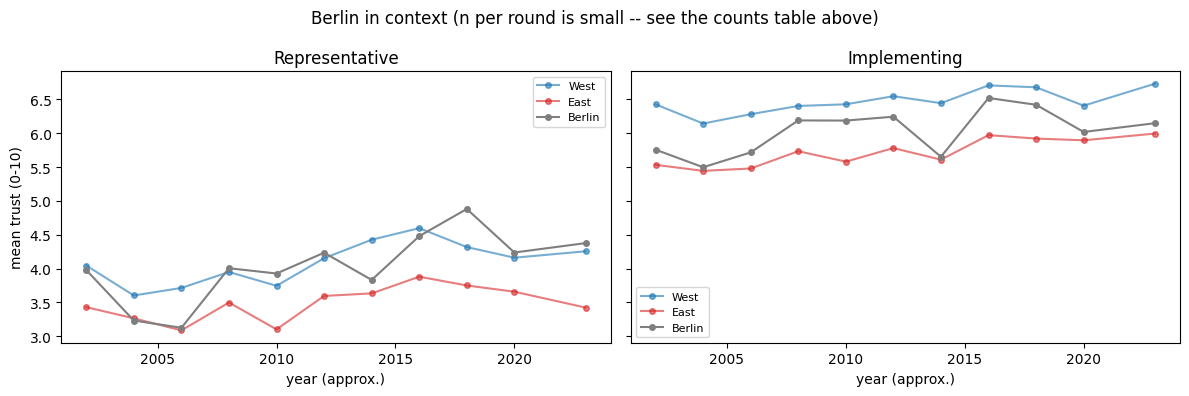

In [10]:
# Berlin, shown separately since it cannot be split into former East/West.
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (col, title) in zip(axes, DIMS.items()):
    d = by_region(col, regions=("West", "East", "Berlin"))
    for reg in ["West", "East", "Berlin"]:
        s = d[d["ew"] == reg]
        ax.plot(s["year"], s["mean"], "-o", ms=4, color=REGION_COLORS[reg], label=reg,
                alpha=0.6 if reg != "Berlin" else 1.0)
    ax.set_title(title)
    ax.set_xlabel("year (approx.)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("mean trust (0-10)")
fig.suptitle("Berlin in context (n per round is small -- see the counts table above)")
fig.tight_layout()

## Summary

**The divide is real, large, and persistent.** West Germany sits above East Germany on both
dimensions in every single one of the 11 rounds. The gap averages ~0.6 points on the 0–10 scale
for representative institutions (range 0.34–0.83) and ~0.75 points for implementing institutions
(range 0.51–0.89).

**It is not closing.** Over 21 years the representative gap runs 0.61 (2002) → 0.83 (2023) and
the implementing gap 0.89 → 0.74. Both series wander inside their error bars with no trend;
whatever the divide is, two decades have not eroded it.

**Both regions gained trust, unequally.** Representative trust rose +0.36 in the West but only
+0.12 in the East, which is why the gap is, if anything, slightly wider at the end.

**The East is coherent, and its bottom end is distinctly low.** Pooling rounds 9–11, the four
lowest-trust Länder are Sachsen (3.50), Thüringen (3.52), Sachsen-Anhalt (3.55) and
Mecklenburg-Vorpommern (3.74) — all East. Brandenburg (3.85) overlaps the West's low end
(Saarland 3.84, Bayern 4.00), so the split is a strong regularity rather than a clean partition.
Berlin (4.38) sits in the upper half, which is a reminder that it is a mixed case and rightly
excluded from the contrast.

### The finding that matters for the previous notebook

The East oversample ending between rounds 8 and 9 (33% → 14% of the sample) means **unweighted
German aggregates are not comparable across that boundary**. For representative trust,
2002 → 2023:

| series | change |
| --- | --- |
| national, unweighted | **+0.47** |
| national, survey-weighted | **+0.16** |
| East only | +0.12 |
| West only | +0.36 |

The unweighted national rise exceeds *both* regions' own rises — the signature of a composition
shift, not an attitude shift. The model in `political_trust_de_fr.ipynb` is unweighted, so its
headline of rising German representative trust (+0.50 latent sd) is materially inflated. It
should be re-run with survey weights, or with region in the model, before being relied on. The
French result is unaffected — this is a German sampling-design issue.

### What this notebook deliberately does not do

- No model. These are weighted sample means with naive SEs that ignore the survey's clustering
  and stratification, so the bands are somewhat too narrow.
- No latent trait, so items are simply averaged — which implicitly assumes the 0–10 scale is
  used the same way in both regions. That is far safer here than between Germany and France
  (same questionnaire, same language, same fieldwork), but it is untested.
- Berlin is excluded from the East/West contrast and cannot be split from this data subset;
  ESS's `intewde` variable would resolve it.
- Several Länder have small per-round samples (Bremen n=55 even pooled over three rounds). The
  Bundesland chart is a heterogeneity check, not a ranking to be taken literally.